## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             precision_recall_curve)

RANDOM_STATE = 42

In [3]:


!pip install ucimlrepo

## 2. Load & clean data

In [4]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=468)

X = dataset.data.features
y = dataset.data.targets

df = X.copy()
df['Revenue'] = y['Revenue']

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [8]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [9]:
df.isna().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(125)

In [12]:
df[df.duplicated()]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [13]:
df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean["Weekend"] = df_clean["Weekend"].astype(int)
print("Clean shape:", df_clean.shape)

print("\nClass balance (%):")
print(df_clean["Revenue"].value_counts(normalize=True) * 100)

Clean shape: (12205, 18)

Class balance (%):
Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64


## 3. EDA (أمثلة - كمّلي عليها وسجّلي 3-5 insights)

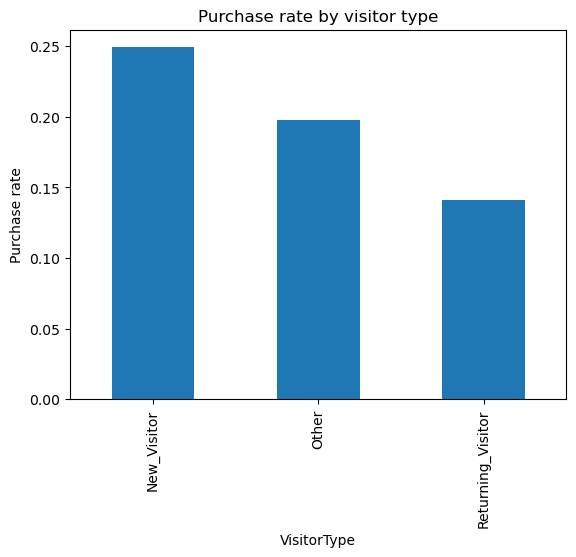

In [14]:
df_clean.groupby("VisitorType")["Revenue"].mean().plot(kind="bar", title="Purchase rate by visitor type")
plt.ylabel("Purchase rate"); plt.show()

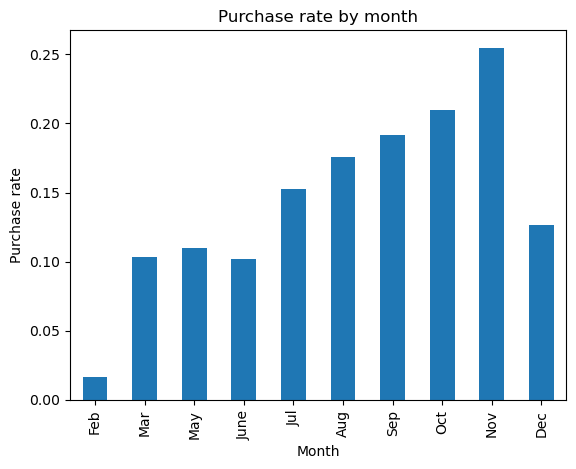

In [15]:
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_clean.groupby("Month")["Revenue"].mean().reindex(order).plot(kind="bar", title="Purchase rate by month")
plt.ylabel("Purchase rate"); plt.show()

In [ ]:
df_clean.boxplot(column="PageValues", by="Revenue", showfliers=False)
plt.title("PageValues by purchase"); plt.suptitle(""); plt.show()

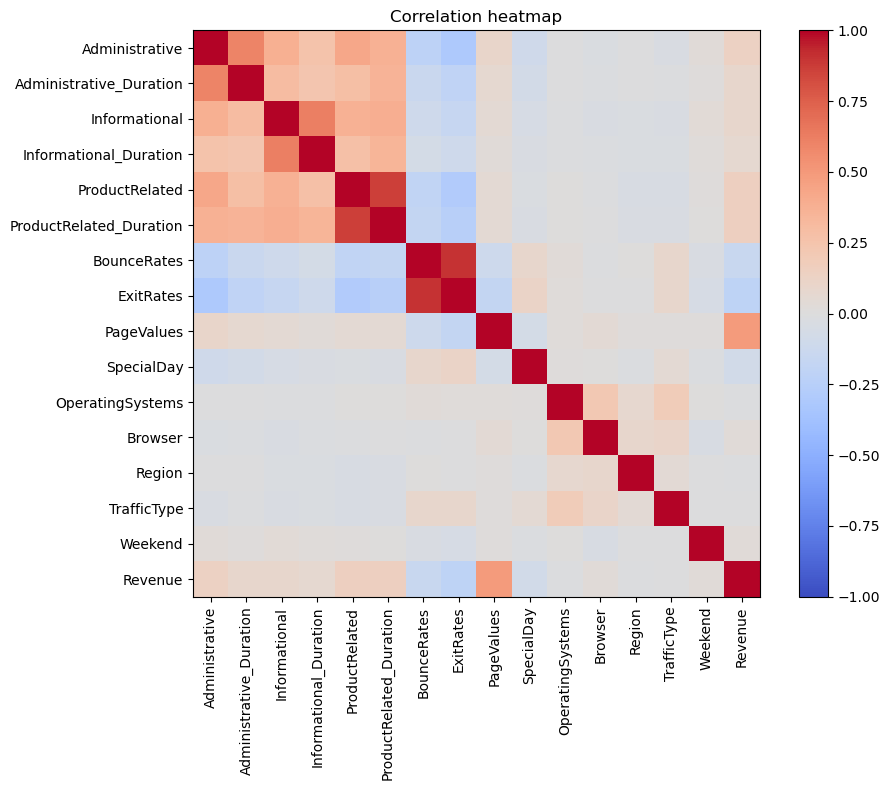

In [16]:
corr = df_clean.select_dtypes("number").assign(Revenue=df_clean["Revenue"].astype(int)).corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

## 4. X, y and train/test split (قبل أي preprocessing)

In [17]:
X = df_clean.drop(columns="Revenue")
y = df_clean["Revenue"].astype(int)

print(X.shape, y.shape)          # لازم: (12205, 17) (12205,)
assert y.ndim == 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(12205, 17) (12205,)
(9764, 17) (2441, 17)


## 5. Preprocessing pipeline

In [18]:
code_cols = ["OperatingSystems", "Browser", "Region", "TrafficType"]
cat_cols = ["Month", "VisitorType"] + code_cols
num_cols = [
    "Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
    "PageValues", "SpecialDay", "Weekend",
    "TotalPages", "TotalDuration", "AvgTimePerPage",
]

def add_features(d):
    d = d.copy()
    d["TotalPages"] = d["Administrative"] + d["Informational"] + d["ProductRelated"]
    d["TotalDuration"] = (d["Administrative_Duration"] + d["Informational_Duration"]
                          + d["ProductRelated_Duration"])
    d["AvgTimePerPage"] = (d["TotalDuration"] / d["TotalPages"].replace(0, np.nan)).fillna(0)
    return d

def codes_to_str(d):
    d = d.copy()
    d[code_cols] = d[code_cols].astype(str)
    return d

def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("codes", FunctionTransformer(codes_to_str)),
        ("prep", prep),
        ("model", model),
    ])

## 6. Baseline + 3 models

In [19]:
def evaluate(name, pipe):
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    row = {"model": name,
           "F1": f1_score(y_test, pred, zero_division=0),
           "Recall": recall_score(y_test, pred, zero_division=0),
           "Precision": precision_score(y_test, pred, zero_division=0),
           "ROC-AUC": roc_auc_score(y_test, proba)}
    return row

rows = [
    evaluate("Baseline", make_pipeline(DummyClassifier(strategy="most_frequent"))),
    evaluate("Logistic Regression", make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))),
    evaluate("Random Forest", make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                   random_state=RANDOM_STATE, n_jobs=-1))),
    evaluate("Gradient Boosting", make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE))),
]
results = pd.DataFrame(rows).round(3)
results

,model,F1,Recall,Precision,ROC-AUC
0,Baseline,0.000,0.000,0.000,0.500
1,Logistic Regression,0.619,0.796,0.507,0.910
2,Random Forest,0.609,0.513,0.748,0.925
3,Gradient Boosting,0.673,0.639,0.711,0.936


## 7. Hyperparameter tuning (Gradient Boosting) intrain 

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    param_distributions={
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.7, 0.85, 1.0],
    },
    n_iter=15, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", search.best_score_)
print("Best params:", search.best_params_)
best_gb = search.best_estimator_

Best CV ROC-AUC: 0.9302028689877021
Best params: {'model__subsample': 0.85, 'model__n_estimators': 200, 'model__max_depth': 4, 'model__learning_rate': 0.01}


## 8. Threshold tuning (من الـ train بالـ cross-validation)

In [21]:
oof = cross_val_predict(best_gb, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
THRESHOLD = float(thr[f1s.argmax()])
print("Chosen threshold:", round(THRESHOLD, 3))

Chosen threshold: 0.338


## 9. Final evaluation على الـ test set

Test ROC-AUC: 0.9367
              precision    recall  f1-score   support

 No purchase       0.95      0.93      0.94      2059
    Purchase       0.67      0.73      0.70       382

    accuracy                           0.90      2441
   macro avg       0.81      0.83      0.82      2441
weighted avg       0.90      0.90      0.90      2441



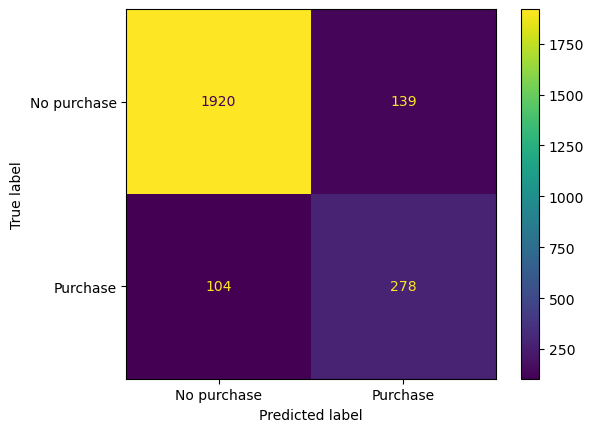

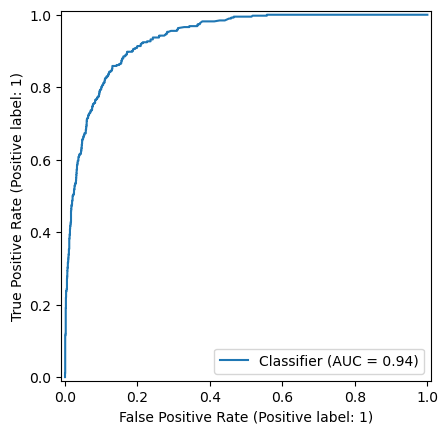

In [22]:
proba = best_gb.predict_proba(X_test)[:, 1]
pred_new = (proba >= THRESHOLD).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, pred_new, target_names=["No purchase", "Purchase"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_new),
                       display_labels=["No purchase", "Purchase"]).plot()
plt.show()

RocCurveDisplay.from_predictions(y_test, proba)
plt.show()

## 10. Error analysis

In [ ]:
errors = X_test.copy()
errors["y_true"] = y_test.values
errors["proba"] = proba
errors["pred"] = pred_new

fn = errors[(errors.y_true == 1) & (errors.pred == 0)]   # مشترين فوّتهم الموديل
fp = errors[(errors.y_true == 0) & (errors.pred == 1)]   # قال هيشتري وماشتراش
print("False negatives:", len(fn), "| False positives:", len(fp))

print("\nVisitorType في الـ false negatives:")
print(fn["VisitorType"].value_counts(normalize=True).round(2))

print("\nPageValues المتوسط:")
print("Correctly found buyers :", errors[(errors.y_true == 1) & (errors.pred == 1)]["PageValues"].mean().round(2))
print("Missed buyers          :", fn["PageValues"].mean().round(2))

## 11. Feature importance

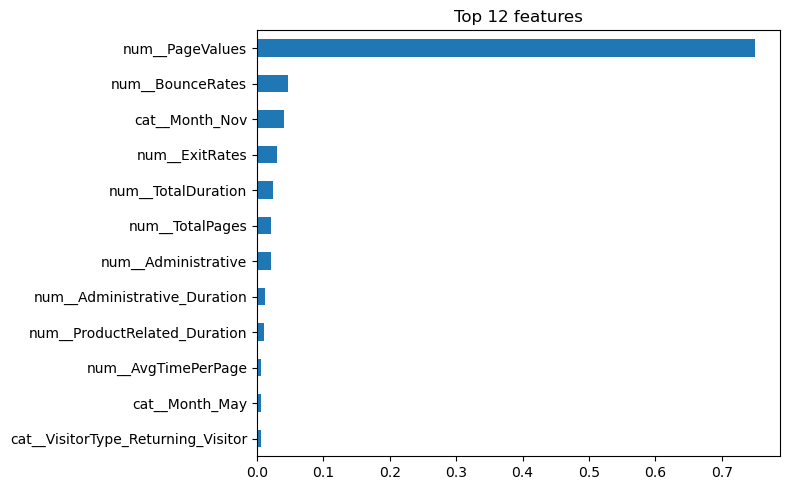

In [23]:
model = best_gb.named_steps["model"]
names = best_gb.named_steps["prep"].get_feature_names_out()
imp = pd.Series(model.feature_importances_, index=names).sort_values()
imp.tail(12).plot(kind="barh", figsize=(8, 5), title="Top 12 features")
plt.tight_layout(); plt.show()

## 12. Save model for the app

In [24]:
joblib.dump({"pipeline": best_gb, "threshold": THRESHOLD}, "model.joblib")
print("Saved model.joblib")

Saved model.joblib


In [25]:
bundle = joblib.load("model.joblib")
print("Threshold:", bundle["threshold"])
print(bundle["pipeline"].predict_proba(X_test.head(3)))

Threshold: 0.33786099207088927
[[0.92863533 0.07136467]
 [0.9485015  0.0514985 ]
 [0.95215867 0.04784133]]


In [1]:
import sklearn
print(sklearn.__version__)

1.6.1
